In [1]:

import os
import h5py
import requests
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive,userdata
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
baseUrl = 'http://www.tng-project.org/api/'
headers = {"api-key":userdata.get("TNG_API_KEY")}

In [3]:
def get(path, params=None):
    # make HTTP GET request to path
    r = requests.get(path, params=params, headers=headers)

    # raise exception if response code is not HTTP SUCCESS (200)
    r.raise_for_status()

    if r.headers['content-type'] == 'application/json':
        return r.json() # parse json responses automatically

    if 'content-disposition' in r.headers:
        filename = r.headers['content-disposition'].split("filename=")[1]
        with open(filename, 'wb') as f:
            f.write(r.content)
        return filename # return the filename string

    return r

In [4]:
r = get(baseUrl)

In [5]:
os.chdir("/content/drive/MyDrive/TNGdata")

In [6]:
data = np.load("subhalo_data_with_bhmasses.npz")
data = data["data"]

sfrs = data[:,0,0]
bhmdots = data[:,0,1]
mass_stars = data[:,0,2]
mass_bhmdots = data[:,0,3]

mean_b_fields = data[:,0,-2]
median_b_fields = data[:,0,-1]

normalized_sfrs = sfrs / mass_stars
normalized_bhmdots = bhmdots / mass_bhmdots

/tmp/ipykernel_459/3254282534.py:13: RuntimeWarning: invalid value encountered in divide
  normalized_bhmdots = bhmdots / mass_bhmdots


In [7]:
valid_b_mask = (mean_b_fields > 0)
clean_mean_b = mean_b_fields[valid_b_mask]

In [8]:
valid_scatter_mask = (mean_b_fields > 0) & (sfrs >= 0) & (bhmdots >= 0) & (mass_stars > 0) & (mass_bhmdots > 0)

clean_b = mean_b_fields[valid_scatter_mask]
clean_norm_bhmdot = normalized_bhmdots[valid_scatter_mask]

<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_459/2434695065.py:11: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(mean_val_micro, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val_micro:.2f} $\mu$G')
/tmp/ipykernel_459/2434695065.py:12: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(median_val_micro, color='orange', linestyle='-', linewidth=2, label=f'Median: {median_val_micro:.2f} $\mu$G')
/tmp/ipykernel_459/2434695065.py:15: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Mean Physical B-field strength [$\mu$G]')


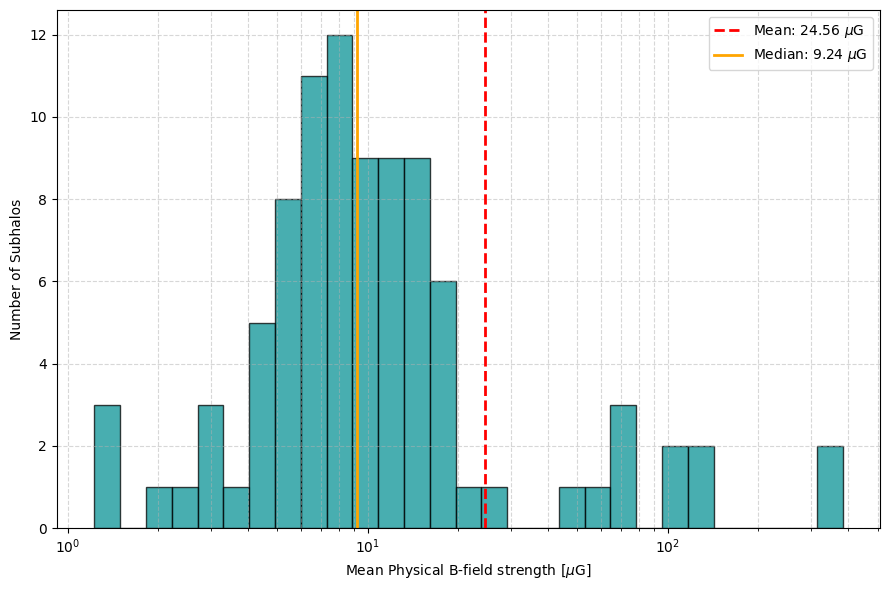

In [9]:
# Convert the B-field values from Gauss to microGauss for more standard plotting
clean_mean_b_micro = clean_mean_b * 1e6
clean_b_micro = clean_b * 1e6

plt.figure(figsize=(9, 6))
bins = np.logspace(np.log10(clean_mean_b_micro.min()), np.log10(clean_mean_b_micro.max()), 30)
plt.hist(clean_mean_b_micro, bins=bins, color='#0a9396', alpha=0.75, edgecolor='black')

mean_val_micro = np.mean(clean_mean_b_micro)
median_val_micro = np.median(clean_mean_b_micro)
plt.axvline(mean_val_micro, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val_micro:.2f} $\mu$G')
plt.axvline(median_val_micro, color='orange', linestyle='-', linewidth=2, label=f'Median: {median_val_micro:.2f} $\mu$G')

plt.xscale('log')
plt.xlabel('Mean Physical B-field strength [$\mu$G]')
plt.ylabel('Number of Subhalos')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("mean_B_fields_histogram_micro.png", dpi=300)
plt.show()

<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_459/1820093527.py:6: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Mean Physical B-field [$\mu$G]')


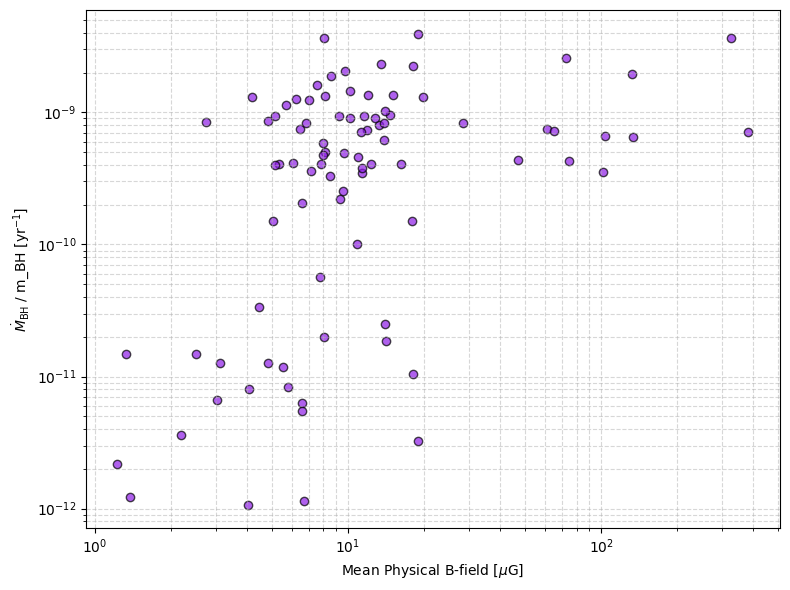

In [10]:
# 2. Replot normalized BHMDOT vs B-field
plt.figure(figsize=(8, 6))
plt.scatter(clean_b_micro, clean_norm_bhmdot, color='#8e1ce6', alpha=0.7, edgecolors='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mean Physical B-field [$\mu$G]')
plt.ylabel(r'$\dot{M}_{\text{BH}}$ / m_BH [$\text{yr}^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("norm_bhmdot_vs_bfield_micro.png", dpi=300)
plt.show()

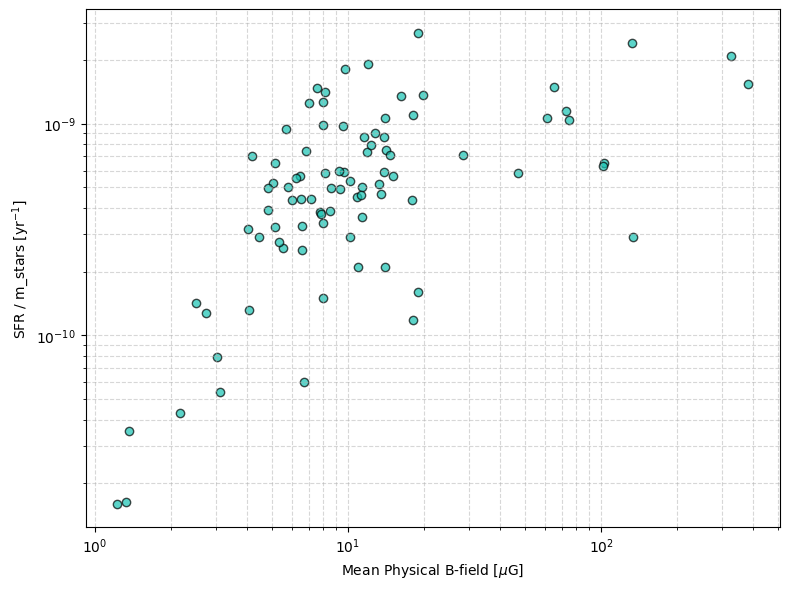

In [11]:
clean_norm_sfr = normalized_sfrs[valid_scatter_mask]

plt.figure(figsize=(8, 6))
plt.scatter(clean_b_micro, clean_norm_sfr, color='#17c3b2', alpha=0.7, edgecolors='black')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mean Physical B-field [$\\mu$G]')
plt.ylabel('SFR / m_stars [yr$^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("norm_sfr_vs_bfield_micro.png", dpi=300)
plt.show()